Бизнес-кейс: «Подозрительные транзакции»

В банках мошенники часто используют паттерн «дробление сумм»: они делают несколько мелких переводов подряд (например, 3 перевода по 9000 рублей), чтобы обойти лимит на один перевод в 10 000 рублей.

Нам нужно найти клиентов, которые сделали 3 или более переводов в течение одного дня, и сумма каждой операции при этом меньше 10 000 рублей.

Для анализа использовалась таблица в PostgreSQL:

**1. `transactions` (Транзакции)**
| Поле | Тип | Описание |
| :--- | :--- | :--- |
| `transaction_id` | INTEGER (PK) | Уникальный ID транзакции |
| `client_id` | INTEGER | Уникальный ID клиента |
| `transaction_date` | TIMESTAMP | Дата и время транзакции |
| `amount` | INTEGER | Стоимость транзакции |

## Как это работает
1. Данные агрегируются через SQL-запрос (Поиск клиентов у которых 3 и более транзакции в 1 день стоимостью меньше 10000).
2. Результат выгружается в CSV и загружается в Jupyter Notebook.

1. Загружаем данные от SQL

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Загрузка данных
df_transactions=pd.read_csv('suspicious_transactions.csv')
print("Данные для анализа:")
print(df_transactions)

Данные для анализа:
   client_id transaction_date  count_tr
0        101       2024-05-01         3
1        104       2024-05-02         3


In [2]:
# 2. Переименовываем столбцы
df_transactions.columns = ['client','date','count']
print("Данные для анализа:")
print(df_transactions)

Данные для анализа:
   client        date  count
0     101  2024-05-01      3
1     104  2024-05-02      3


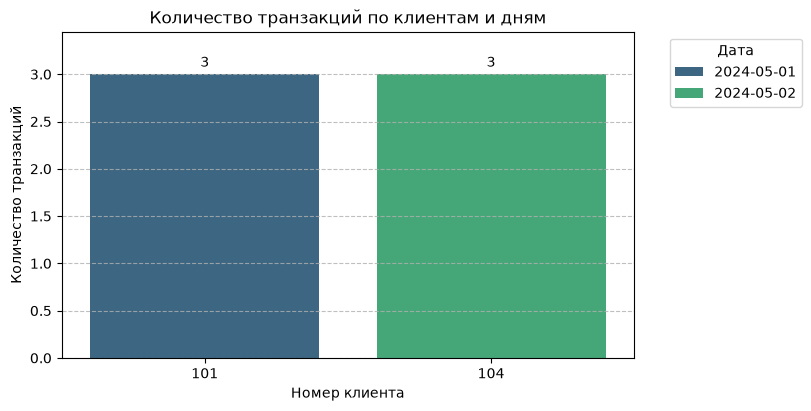

In [11]:
# 3. Строим столбчатую диаграмму: количество транзакций по клиентам и дням
plt.figure(figsize=(8,4),constrained_layout=True) #constrained_layot=True Подстройка изображения чтоб легенда за графиком влезла
ax=sns.barplot(data=df_transactions, x='client', y='count', hue='date', palette='viridis')
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f',padding=3,)

plt.title('Количество транзакций по клиентам и дням')
plt.xlabel('Номер клиента')
plt.ylabel('Количество транзакций')
plt.legend(title='Дата', bbox_to_anchor=(1.05,1),loc='upper left') #bbox_to_anchor=(координаты по осям х, у) для вынесения легенды за график
plt.grid(axis='y',linestyle='--',alpha=0.8)
plt.ylim(0, df_transactions['count'].max() * 1.15)
plt.show()


Выводы по анализу подозрительных транзакций:

1. **Клиент 101** 1 мая 2024 совершил 3 подозрительных транзакции.
2. **Клиент 104** 1 мая 2024 совершил 3 подозрительных транзакции.